# Recurrent LIF Network — g = 5.5 (relative inhibitory strength)

Original recurrent leaky integrate-and-fire network, condition `g = 5.5`.

Reference: Dummer et al. (2014), linked below.

https://www.frontiersin.org/journals/computational-neuroscience/articles/10.3389/fncom.2015.50104/full
https://people.physik.hu-berlin.de/~lindner/PDF/Dummer_etal_FrontCN_2014.PDF

## Environment setup

Install the dependencies from `requirements.txt` before running this notebook. The original model and simulation cells below are unchanged apart from the condition-specific `g` value.


In [1]:
! pip install brian2 -q

In [2]:
# Store outputs beside the notebook without cloning or linking to another notebook.
from pathlib import Path
OUTPUT_DIR = Path.cwd() / 'G5.5_results'
FIGURES_DIR = OUTPUT_DIR / 'figures'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
CONDITION = 'G5.5'


In [3]:
from brian2 import *
import numpy as np
import matplotlib.pyplot as plt

from scipy.signal import welch
from scipy.integrate import quad
from scipy.special import erfc
from scipy.optimize import brentq
from scipy.fft import fft
from scipy.ndimage import gaussian_filter1d

import warnings

warnings.filterwarnings('ignore')
prefs.codegen.target = 'cython'

##spiking neural network

FIGURE 8B — recurrent LIF network, inhibitory strength G5.5:
- g = 5.5
- vr = 10
-

excitatory population = 100,000 \
inhibitory population = 2,500

In [4]:
# Standalone recurrent-network setup. No repository or cache is required.
start_scope()
defaultclock.dt = 0.1 * ms
seed(4321)

N_E = 100000
gamma = 0.25
N_I = int(gamma * N_E)
N = N_E + N_I

epsilon = 0.01
C_E = int(epsilon * N_E)
C_I = int(epsilon * N_I)

tau = 20 * ms
theta = 20 * mV
V_r = 10.0 * mV
tau_rp = 2 * ms

J = 0.1 * mV
g = 5.5
D = 1.5 * ms
RI = 30 * mV
sim_time = 3000 * ms

neurons = NeuronGroup(
    N, name='sc_neurons',
    model='dv/dt = (-v + RI) / tau : volt (unless refractory)',
    threshold='v > theta',
    reset='v = V_r',
    refractory=tau_rp,
    method='euler',
)
neurons.v = 'rand() * mV'
exc_neurons = neurons[:N_E]
inh_neurons = neurons[N_E:]


In [5]:
# Recurrent synapses with the fixed in-degree used in the original model.
exc_syn = Synapses(exc_neurons, neurons, name="sc_exc", on_pre="v += J", delay=D)
inh_syn = Synapses(inh_neurons, neurons, name="sc_inh", on_pre="v += -g*J", delay=D)

targets_E = np.repeat(np.arange(N), C_E)
targets_I = np.repeat(np.arange(N), C_I)
sources_E = np.random.randint(0, N_E, size=N * C_E)
sources_I = np.random.randint(0, N_I, size=N * C_I)
exc_syn.connect(i=sources_E, j=targets_E)
inh_syn.connect(i=sources_I, j=targets_I)


In [6]:
# Run directly and checkpoint every simulated second.
from pathlib import Path
checkpoint_dir = OUTPUT_DIR / 'checkpoints'
checkpoint_dir.mkdir(parents=True, exist_ok=True)

rate_mon = PopulationRateMonitor(neurons)
spike_mon = SpikeMonitor(neurons)
net = Network(neurons, exc_syn, inh_syn, rate_mon, spike_mon)

checkpoint_files = sorted(checkpoint_dir.glob('network-*.brian'))
start_s = 0.0
if checkpoint_files:
    latest = checkpoint_files[-1]
    net.restore('checkpoint', filename=str(latest), restore_random_state=True)
    start_s = float(net.t / second)
    print(f'Resuming recurrent network at {start_s:g} s')

target_s = float(sim_time / second)
while start_s < target_s - 1e-12:
    amount_s = min(1.0, target_s - start_s)
    net.run(amount_s * second)
    start_s = float(net.t / second)

    network_file = checkpoint_dir / f'network-{start_s:07.3f}s.brian'
    net.store('checkpoint', filename=str(network_file))
    np.savez_compressed(
        checkpoint_dir / f'monitor-{start_s:07.3f}s.npz',
        spike_indices=np.asarray(spike_mon.i),
        spike_times_ms=np.asarray(spike_mon.t / ms),
        population_rate_time_ms=np.asarray(rate_mon.t / ms),
        population_rate_hz=np.asarray(rate_mon.rate / Hz),
    )
    print(f'Checkpoint: recurrent {start_s:g}/{target_s:g} s')

# Final monitor checkpoint always marks a completed run.
np.savez_compressed(
    OUTPUT_DIR / 'G5.5_completed_monitor.npz',
    spike_indices=np.asarray(spike_mon.i),
    spike_times_ms=np.asarray(spike_mon.t / ms),
    population_rate_time_ms=np.asarray(rate_mon.t / ms),
    population_rate_hz=np.asarray(rate_mon.rate / Hz),
)


Checkpoint: recurrent 1/3 s
Checkpoint: recurrent 2/3 s
Checkpoint: recurrent 3/3 s


In [7]:
# Extract spike trains from the monitor
spike_trains = spike_mon.spike_trains()
cv_list = []

# Iterate through each neuron's spike train
for neuron_idx, train in spike_trains.items():

    # Ensure there are enough spikes to calculate an ISI
    if len(train) > 2:

        # Calculate Inter-Spike Intervals (ISIs)
        isi = np.diff(train / ms)

        # Calculate CV: Standard Deviation / Mean
        cv = np.std(isi) / np.mean(isi)
        cv_list.append(cv)

# Calculate the network-wide average CV
if cv_list:
    mean_cv = np.mean(cv_list)
    print(f"Average Network CV: {mean_cv:.3f}")
else:
    print("Not enough spikes to calculate CV.")


average_firing_rate = np.mean(rate_mon.rate)
print(f"Average Firing Rate: {average_firing_rate:.2f} Hz")

Average Network CV: 0.474
Average Firing Rate: 17.18 Hz


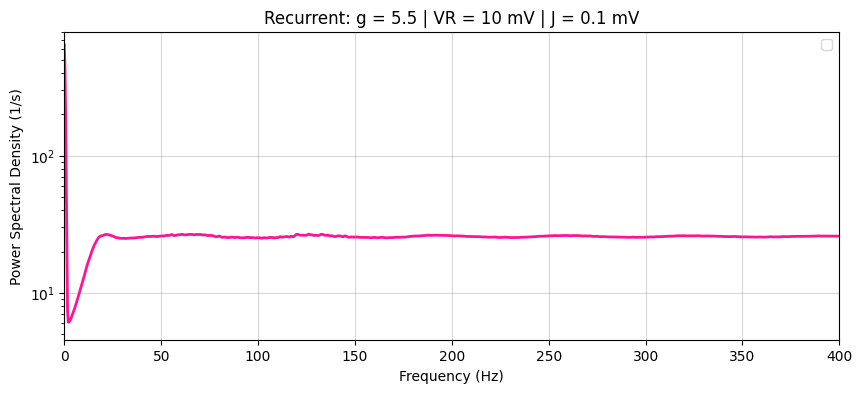

In [8]:
num_time_bins = int(sim_time/ms)
neuron_indices = np.asarray(spike_mon.i)
spike_times = np.asarray(spike_mon.t / ms).astype(int)
valid = (spike_times >= 0) & (spike_times < num_time_bins)

pop_activity = np.zeros(num_time_bins, dtype=np.uint32)
np.add.at(pop_activity, spike_times[valid], 1)

Savg = np.zeros(num_time_bins, dtype=np.float64)
block_size = 1000
for start in range(0, N, block_size):
    stop = min(start + block_size, N)
    block_mask = (neuron_indices >= start) & (neuron_indices < stop)
    block_i = neuron_indices[block_mask] - start
    block_t = spike_times[block_mask]
    valid_block = (block_t >= 0) & (block_t < num_time_bins)
    block_spikes = np.zeros((stop - start, num_time_bins), dtype=np.uint8)
    block_spikes[block_i[valid_block], block_t[valid_block]] = 1
    y_tilde = fft(block_spikes, axis=1)
    Savg += np.sum(np.abs(y_tilde)**2 / 2, axis=0)
Savg /= N
# Plotting

f_brian = np.arange(0, len(Savg)) * (1.0 / sim_time)


# --- 2. Smooth the data ---
sigma_val = 1.5
Savg_smooth = gaussian_filter1d(Savg, sigma=sigma_val)


plt.figure(figsize=(10, 4))
plt.semilogy(f_brian, Savg_smooth, color='deeppink', lw =2)
plt.title(f"Recurrent: g = {g} | VR = {int(V_r/mV)} mV | J = {J/mV:.1f} mV")
plt.xlim([0, 400])
plt.ylim([0, 800])
plt.xlabel('Frequency (Hz)')
plt.ylabel('Power Spectral Density (1/s)')
plt.grid(True, alpha=0.5)
plt.legend()
plt.savefig(FIGURES_DIR / "G5.5_cell_11.png", dpi=150)
plt.show()


In [9]:
# Store outputs beside the notebook without cloning or linking to another notebook.
from pathlib import Path
OUTPUT_DIR = Path.cwd() / 'G5.5_results'
FIGURES_DIR = OUTPUT_DIR / 'figures'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
CONDITION = 'G5.5'


# Gaussian Approximation:

**self consistent iteritive scheme**

In [10]:
# Numerical/Iterative Constraints
T_trial = 500.0
dt_sec = 0.0001
N_steps = int(T_trial / dt_sec)
f_cur = np.fft.rfftfreq(N_steps, d=dt_sec)

# Dimensionless equivalents
tau_val = 0.020
vT_val = 0.020
vR_val = 0.010
tau_ref_val = 0.002
J_val = 0.0001
g_val = 5.5
RI_val = 0.030

In [11]:
def mu_D_stats(nu_in):
    gamma_frac = 0.25
    mu = RI_val + C_E * J_val * tau_val * (1.0 - gamma_frac * g_val) * nu_in
    return mu

def simulate_lif_vectorized(RI_array):
    v = vR_val
    ref_steps = 0
    spike_indices = []

    dt_over_tau = dt_sec / tau_val
    ref_limit = int(tau_ref_val / dt_sec)

    for n in range(N_steps):
        if ref_steps > 0:
            ref_steps -= 1
            v = vR_val
        else:
            v += (-v + RI_array[n]) * dt_over_tau
            if v >= vT_val:
                spike_indices.append(n)
                v = vR_val
                ref_steps = ref_limit

    return np.array(spike_indices) * dt_sec

def generate_colored_noise(S_x_prev, f_prev, nu_in):
    mu = mu_D_stats(nu_in)
    coeff = (C_E * J_val**2 + C_I * (g_val * J_val)**2) * tau_val**2

    f_gen = np.fft.rfftfreq(N_steps, d=dt_sec)
    S_eta = coeff * np.interp(f_gen, f_prev, S_x_prev, left=S_x_prev[0], right=S_x_prev[-1])

    amp = np.sqrt(np.maximum(S_eta, 0) * N_steps / (2.0 * dt_sec))
    phases = np.random.uniform(0, 2.0 * np.pi, len(f_gen))

    X = amp * np.exp(1j * phases)
    X[0] = 0.0

    eta = np.fft.irfft(X, n=N_steps) + mu
    return eta

def psd_from_spikes(spike_times, nperseg=8192):
    x = np.zeros(N_steps)
    idx = (spike_times / dt_sec).astype(int)
    x[idx[(idx >= 0) & (idx < N_steps)]] = 1.0 / dt_sec
    f, S = welch(x, fs=1.0/dt_sec, nperseg=min(N_steps, nperseg), window='hann')
    return f, S


### input = 15 HZ / 15 generations

In [12]:
print("Executing Gaussian Approximation Iterative Scheme...")

# Initial guess for the firing rate
nu_in = 15.0
n_gen = 15

# Initialize list to store CVs across generations if you want to plot them later
cv_gen_list = []


for gen in range(1, n_gen + 1):
    if gen == 1:
        exc_spikes = np.random.poisson(C_E * nu_in * dt_sec, N_steps)
        inh_spikes = np.random.poisson(C_I * nu_in * dt_sec, N_steps)
        RI_input = ((exc_spikes * J_val - inh_spikes * g_val * J_val) / dt_sec) * tau_val + RI_val
    else:
        RI_input = generate_colored_noise(S_cur, f_cur, nu_in)

    sp = simulate_lif_vectorized(RI_input)
    nu_in = len(sp) / T_trial
    f_cur, S_cur = psd_from_spikes(sp)

    # --- CV Calculation ---
    if len(sp) > 1:
        isi = np.diff(sp)
        cv = np.std(isi) / np.mean(isi)
    else:
        cv = np.nan # Assign NaN if there aren't enough spikes to calculate CV

    cv_gen_list.append(cv)

    print(f"--> Generation {gen}: Calculated Mean Rate = {nu_in:.1f} Hz | CV = {cv:.3f}")


Executing Gaussian Approximation Iterative Scheme...
--> Generation 1: Calculated Mean Rate = 21.7 Hz | CV = 0.638
--> Generation 2: Calculated Mean Rate = 6.2 Hz | CV = 0.751
--> Generation 3: Calculated Mean Rate = 45.2 Hz | CV = 0.280
--> Generation 4: Calculated Mean Rate = 0.0 Hz | CV = nan
--> Generation 5: Calculated Mean Rate = 62.9 Hz | CV = 0.000
--> Generation 6: Calculated Mean Rate = 0.0 Hz | CV = nan
--> Generation 7: Calculated Mean Rate = 62.9 Hz | CV = 0.000
--> Generation 8: Calculated Mean Rate = 0.0 Hz | CV = nan
--> Generation 9: Calculated Mean Rate = 62.9 Hz | CV = 0.000
--> Generation 10: Calculated Mean Rate = 0.0 Hz | CV = nan
--> Generation 11: Calculated Mean Rate = 62.9 Hz | CV = 0.000
--> Generation 12: Calculated Mean Rate = 0.0 Hz | CV = nan
--> Generation 13: Calculated Mean Rate = 62.9 Hz | CV = 0.000
--> Generation 14: Calculated Mean Rate = 0.0 Hz | CV = nan
--> Generation 15: Calculated Mean Rate = 62.9 Hz | CV = 0.000


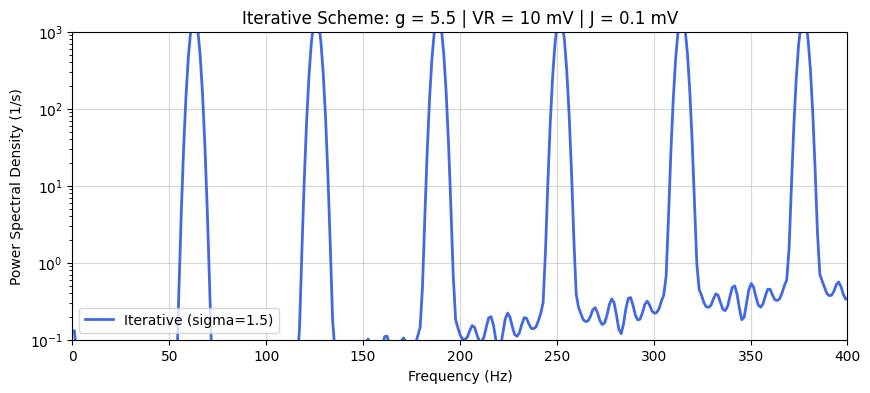

In [13]:
# Smooth and plot the final PSD
sigma_val = 1.5


S_cur_smooth = gaussian_filter1d(S_cur, sigma=sigma_val)
f_cur_smooth = gaussian_filter1d(f_cur, sigma=sigma_val)

plt.figure(figsize=(10, 4))
plt.semilogy(f_cur_smooth, S_cur_smooth, color='royalblue', lw=2, label=f'Iterative (sigma={sigma_val})')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Power Spectral Density (1/s)')
plt.title(f"Iterative Scheme: g = {g_val} | VR = {int(V_r/mV)} mV | J = {J/mV:.1f} mV")
plt.xlim([0, 400])
plt.ylim([0.1, 1000])
plt.legend()
plt.grid(True, alpha=0.5)
plt.savefig(FIGURES_DIR / "G5.5_cell_18.png", dpi=150)
plt.show()

### input = 71HZ / 15 generations

In [14]:
print("Executing Gaussian Approximation Iterative Scheme...")

# Initial guess for the firing rate
nu_in = 71.0
n_gen = 15

# Initialize list to store CVs across generations if you want to plot them later
cv_gen_list = []


for gen in range(1, n_gen + 1):
    if gen == 1:
        exc_spikes = np.random.poisson(C_E * nu_in * dt_sec, N_steps)
        inh_spikes = np.random.poisson(C_I * nu_in * dt_sec, N_steps)
        RI_input = ((exc_spikes * J_val - inh_spikes * g_val * J_val) / dt_sec) * tau_val + RI_val
    else:
        RI_input = generate_colored_noise(S_cur, f_cur, nu_in)

    sp = simulate_lif_vectorized(RI_input)
    nu_in = len(sp) / T_trial
    f_cur, S_cur = psd_from_spikes(sp)

    # --- CV Calculation ---
    if len(sp) > 1:
        isi = np.diff(sp)
        cv = np.std(isi) / np.mean(isi)
    else:
        cv = np.nan # Assign NaN if there aren't enough spikes to calculate CV

    cv_gen_list.append(cv)

    print(f"--> Generation {gen}: Calculated Mean Rate = {nu_in:.1f} Hz | CV = {cv:.3f}")


Executing Gaussian Approximation Iterative Scheme...
--> Generation 1: Calculated Mean Rate = 0.0 Hz | CV = nan
--> Generation 2: Calculated Mean Rate = 62.9 Hz | CV = 0.000
--> Generation 3: Calculated Mean Rate = 0.0 Hz | CV = nan
--> Generation 4: Calculated Mean Rate = 62.9 Hz | CV = 0.000
--> Generation 5: Calculated Mean Rate = 0.0 Hz | CV = nan
--> Generation 6: Calculated Mean Rate = 62.9 Hz | CV = 0.000
--> Generation 7: Calculated Mean Rate = 0.0 Hz | CV = nan
--> Generation 8: Calculated Mean Rate = 62.9 Hz | CV = 0.000
--> Generation 9: Calculated Mean Rate = 0.0 Hz | CV = nan
--> Generation 10: Calculated Mean Rate = 62.9 Hz | CV = 0.000
--> Generation 11: Calculated Mean Rate = 0.0 Hz | CV = nan
--> Generation 12: Calculated Mean Rate = 62.9 Hz | CV = 0.000
--> Generation 13: Calculated Mean Rate = 0.0 Hz | CV = nan
--> Generation 14: Calculated Mean Rate = 62.9 Hz | CV = 0.000
--> Generation 15: Calculated Mean Rate = 0.0 Hz | CV = nan


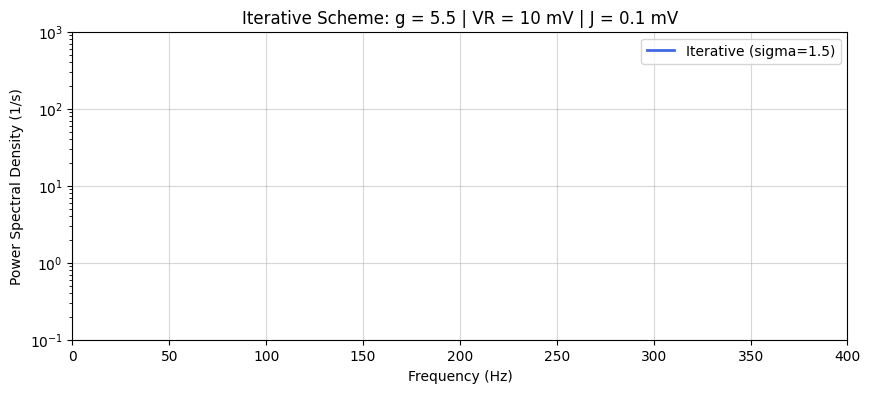

In [15]:
# Smooth and plot the final PSD
sigma_val = 1.5


S_cur_smooth = gaussian_filter1d(S_cur, sigma=sigma_val)
f_cur_smooth = gaussian_filter1d(f_cur, sigma=sigma_val)

plt.figure(figsize=(10, 4))
plt.semilogy(f_cur_smooth, S_cur_smooth, color='royalblue', lw=2, label=f'Iterative (sigma={sigma_val})')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Power Spectral Density (1/s)')
plt.title(f"Iterative Scheme: g = {g_val} | VR = {int(V_r/mV)} mV | J = {J/mV:.1f} mV")
plt.xlim([0, 400])
plt.ylim([0.1, 1000])
plt.legend()
plt.grid(True, alpha=0.5)
plt.savefig(FIGURES_DIR / "G5.5_cell_21.png", dpi=150)
plt.show()

## Superimposing the SSN +  Gaussian Approximation

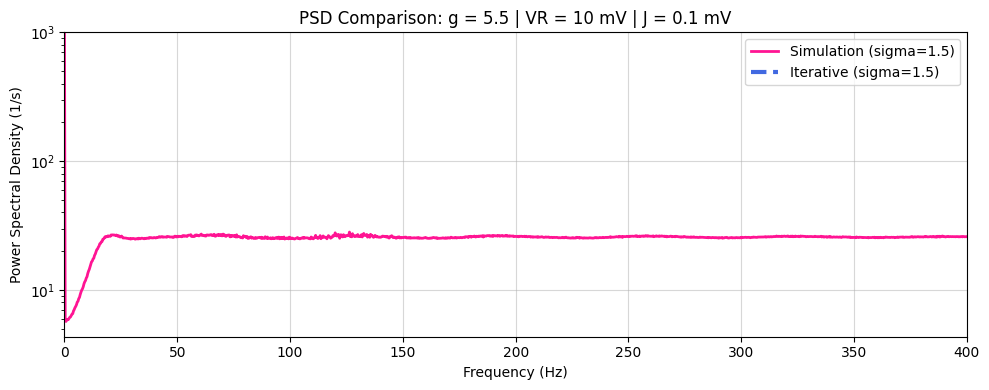

In [16]:
# Initialize a single figure

T_sec = sim_time
f_brian = np.arange(len(Savg)) * (1.0 / T_sec)

plt.figure(figsize=(10, 4))

# 1. Plot the Brian2 Simulation Data
plt.semilogy(f_brian, Savg, color='deeppink', lw=2, label=f'Simulation (sigma={sigma_val})')

# 2. Plot the Iterative Scheme Data
plt.semilogy(f_cur, S_cur_smooth, color='royalblue', lw=3, ls= '--', label=f'Iterative (sigma={sigma_val})')

# Add formatting and labels
plt.xlabel('Frequency (Hz)')
plt.ylabel('Power Spectral Density (1/s)')
plt.title(f"PSD Comparison: g = {g} | VR = {int(V_r/mV)} mV | J = {J/mV:.1f} mV")
plt.xlim([0, 400])
plt.ylim([0, 1000])
plt.legend()
plt.grid(True, alpha=0.5)
plt.tight_layout()
# Render the combined plot
plt.savefig(FIGURES_DIR / "G5.5_cell_23.png", dpi=150)
plt.show()

In [17]:
print(f"Recurrent Network")
print(f" - Rate {average_firing_rate:.2f} Hz")
print(f" - CV: {mean_cv:.3f}")
print("-" * 30)
print(f"Iterative scheme: Generation {n_gen}")
print(f" - Rate = {nu_in:.2f} Hz")
print(f" - CV = {cv_gen_list[14]:.3f}")

Recurrent Network
 - Rate 17.18 Hz
 - CV: 0.474
------------------------------
Iterative scheme: Generation 15
 - Rate = 0.00 Hz
 - CV = nan


In [18]:
# Calculate the error between simulation and iterative scheme
# Strip the unit (Hz) from average_firing_rate for the calculation
avg_rate_val = average_firing_rate / Hz

absolute_error = abs(avg_rate_val - nu_in)
relative_error_percent = (absolute_error / avg_rate_val) * 100

print(f"Simulation Mean Rate: {avg_rate_val:.2f} Hz")
print(f"Iterative Mean Rate:  {nu_in:.2f} Hz")
print("-" * 30)
print(f"Absolute Error: {absolute_error:.4f} Hz")
print(f"Relative Error: {relative_error_percent:.4f}%")

Simulation Mean Rate: 17.18 Hz
Iterative Mean Rate:  0.00 Hz
------------------------------
Absolute Error: 17.1826 Hz
Relative Error: 100.0000%


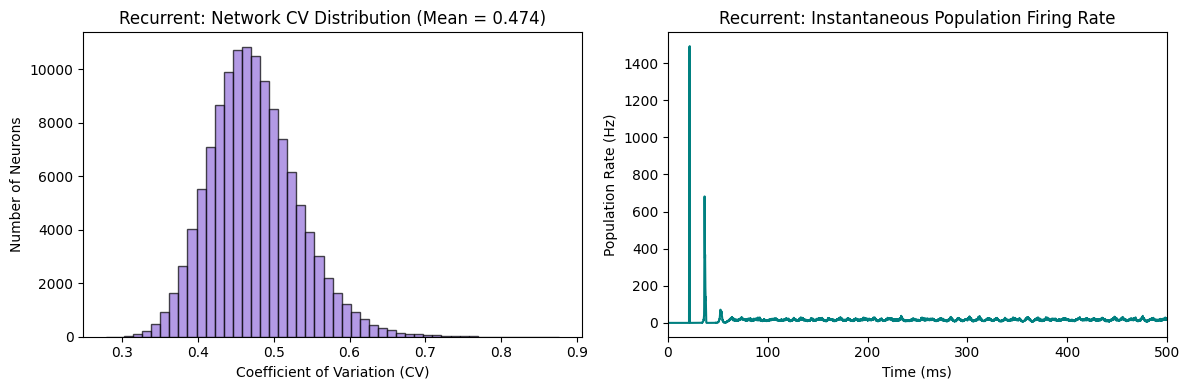

In [19]:
# Create a figure with two subplots
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# --- 1. CV Distribution Histogram ---
axes[0].hist(cv_list, bins=50, color='mediumpurple', edgecolor='black', alpha=0.7)
axes[0].set_xlabel('Coefficient of Variation (CV)')
axes[0].set_ylabel('Number of Neurons')
axes[0].set_title(f'Recurrent: Network CV Distribution (Mean = {mean_cv:.3f})')

# --- 2. Population Firing Rate ---
# Convert time to ms and rate to Hz for plotting
time_ms = rate_mon.t / ms
rate_hz = rate_mon.rate / Hz

axes[1].plot(time_ms, rate_hz, color='teal', lw=1.5)
axes[1].set_xlabel('Time (ms)')
axes[1].set_ylabel('Population Rate (Hz)')
axes[1].set_title('Recurrent: Instantaneous Population Firing Rate')
axes[1].set_xlim([0, 500]) # Zoom in on the first 500ms to see the oscillations clearly

plt.tight_layout()
plt.savefig(FIGURES_DIR / "G5.5_cell_26.png", dpi=150)
plt.show()

### Firing Rate Distribution Comparison
The Recurrent network gives us a *spatial* distribution (different neurons over 3 seconds). The Gaussian iterative scheme gives us a *temporal* distribution (one typical neuron). To compare them, we chop the iterative scheme's 500-second simulation into 3-second intervals.

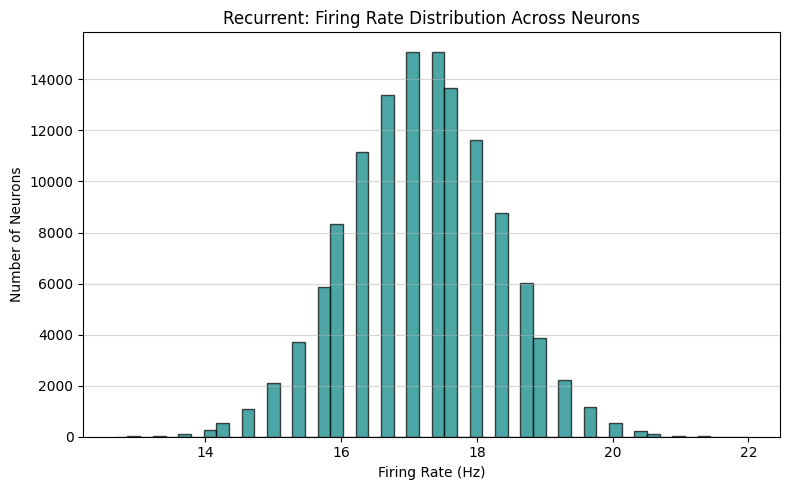

In [20]:
# Calculate firing rate for each neuron in Hz
firing_rates = spike_mon.count / (sim_time / second)

# Plot the firing rate distribution
plt.figure(figsize=(8, 5))
plt.hist(firing_rates, bins=50, color='teal', edgecolor='black', alpha=0.7)
plt.title('Recurrent: Firing Rate Distribution Across Neurons')
plt.xlabel('Firing Rate (Hz)')
plt.ylabel('Number of Neurons')
plt.grid(axis='y', alpha=0.5)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "G5.5_cell_28.png", dpi=150)
plt.show()

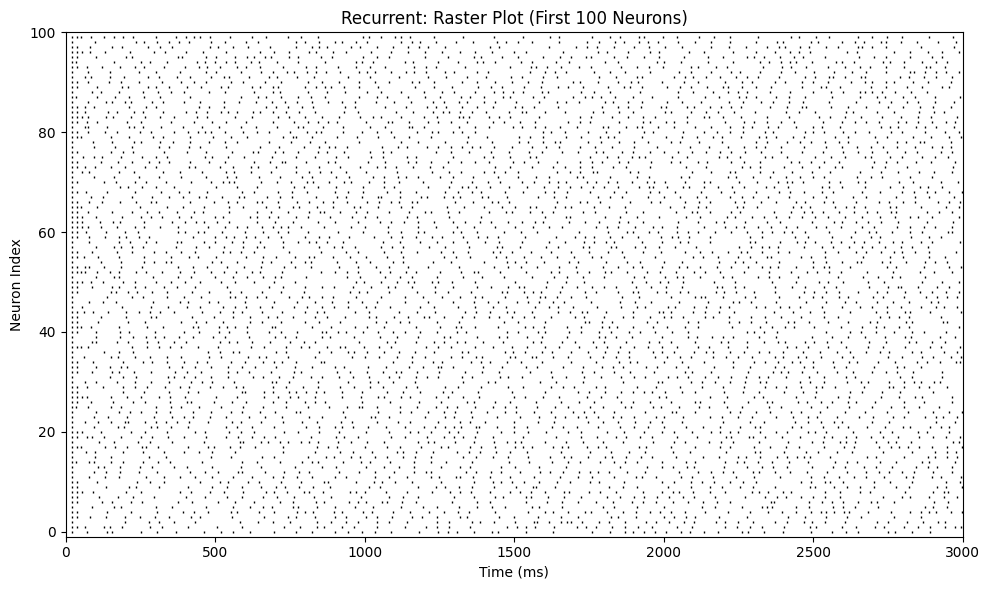

In [21]:
# Filter spikes for the first 100 neurons
neuron_mask = spike_mon.i < 100

plt.figure(figsize=(10, 6))
plt.plot(spike_mon.t[neuron_mask] / ms, spike_mon.i[neuron_mask], '|', color='black', markersize=2)
plt.title('Recurrent: Raster Plot (First 100 Neurons)')
plt.xlabel('Time (ms)')
plt.ylabel('Neuron Index')
plt.xlim(0, sim_time/ms)
plt.ylim(-1, 100)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "G5.5_cell_29.png", dpi=150)
plt.show()

In [22]:
# Compute population activity (total spikes per 1ms time bin)
pop_activity = np.sum(spk_matrix, axis=0)

# Mean-center the population activity to find fluctuations
pop_activity_centered = pop_activity - np.mean(pop_activity)

# Calculate autocorrelation
autocorr = np.correlate(pop_activity_centered, pop_activity_centered, mode='full')

# Extract the positive lags and normalize
autocorr = autocorr[len(autocorr)//2:]
autocorr = autocorr / np.max(autocorr)

# Time lags in ms (since spk_matrix uses 1 ms bins)
lags = np.arange(len(autocorr))

# Plot the autocorrelation
plt.figure(figsize=(10, 4))
plt.plot(lags, autocorr, color='purple', lw=2)
plt.title('Recurrent: Autocorrelation of Population Activity')
plt.xlabel('Lag (ms)')
plt.ylabel('Normalized Autocorrelation')
plt.xlim([0, 100])  # Zoom in on the first 100 ms lag
plt.grid(True, alpha=0.5)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "G5.5_cell_30.png", dpi=150)
plt.show()

NameError: name 'spk_matrix' is not defined

In [ ]:
# Store outputs beside the notebook without cloning or linking to another notebook.
from pathlib import Path
OUTPUT_DIR = Path.cwd() / 'G5.5_results'
FIGURES_DIR = OUTPUT_DIR / 'figures'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
CONDITION = 'G5.5'
